# HMM checkpoint: persistence and performance diagnostics

Read-only analysis of the **latest completed day** in a trusted `checkpoint.pkl`. Change `RESULT_DIR` to point to another run. The pickle contains live Python objects: **never load one from an untrusted source**. All analyses use the checkpoint's saved decision rows, not a potentially lagging `signals.csv`; the historical emission section explicitly replays earlier Student-t fits in memory without modifying the checkpoint.

Interpretation limits: the checkpoint retains only the *current* six models and preprocessors, not the model fitted on every past date. Final transition probabilities describe the final models, **not historical transition paths**. Forecasts and realized performance below are descriptive associations, not evidence that an emission caused better returns. This dataset is the S&P 500 price index (no dividends, interest or trading costs), not SPY.


In [1]:
from pathlib import Path
import pickle
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "data/processed/sp500_index_price.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "notebooks/sp500"))
from paper_regime_experiment import evaluate_signals
from model_evaluation.market_strategy.evaluation import compare_strategies

RESULT_DIR = ROOT / "notebooks/sp500/results/paper_regime_2004_2025"
with (RESULT_DIR / "checkpoint.pkl").open("rb") as handle:
    state = pickle.load(handle)  # Trusted local checkpoints only.
fits = pd.DataFrame(state["rows"]).copy()
fits["date"] = pd.to_datetime(fits["date"])
if (fits.empty or len(fits) != 6 * fits.date.nunique()
        or fits.duplicated(["date", "model", "pca"]).any()
        or fits.date.max() != state["last_date"]):
    raise ValueError("Checkpoint has missing or duplicated daily branches")
prices = (pd.read_csv(ROOT / "data/processed/sp500_index_price.csv",
                      parse_dates=["YYYYMMDD"])
          .set_index("YYYYMMDD")["DlyPrcInd"].astype(float).sort_index())
next_return = prices.pct_change(fill_method=None).shift(-1).reindex(
    pd.DatetimeIndex(fits.date.unique()).sort_values()
)
if next_return.isna().any():
    raise ValueError("A decision has no next-day price return")
print(f"Checkpoint through {state['last_date'].date()}: "
      f"{fits.date.nunique()} decisions, "
      f"{fits.loc[fits.refresh, 'date'].nunique()} fresh-fit dates")
print("The saved transition matrices belong to the LAST completed day's models.")


Checkpoint through 2025-12-30: 5534 decisions, 88 fresh-fit dates
The saved transition matrices belong to the LAST completed day's models.


In [2]:
from paper_regime_experiment import build_observations, label_bull
from run_paper_regime import HALF_LIVES, WINDOWS

features = build_observations(prices, windows=WINDOWS,
                              half_lives=HALF_LIVES).dropna()
initial_days = int(fits.loc[fits.date.eq(fits.date.min()),
                            "training_days"].iloc[0])
initial_end = features.index.get_loc(fits.date.min())
first_training_date = features.index[initial_end - initial_days + 1]
history = features.loc[first_training_date:state["last_date"]]
if len(history) != int(fits.loc[fits.date.eq(state["last_date"]),
                           "training_days"].iloc[0]):
    raise ValueError("Saved training window does not match reconstructed features")
history_returns = prices.pct_change(fill_method=None).reindex(history.index).to_numpy()
rows = []
for (name, use_pca), (model, scaler, pca) in state["branches"].items():
    X = scaler.transform(history)
    if pca is not None:
        X = pca.transform(X)
    bull = label_bull(model, X, history_returns)
    P = model.states.transitions
    key = f"{name} / {'PCA' if use_pca else 'no PCA'}"
    for label, index in (("bull", bull), ("bear", 1 - bull)):
        stay = float(P[index, index])
        rows.append({"model": key, "state": label, "state_index": index,
                     "P(stay)": stay,
                     "implied_days": 1 / (1 - stay) if stay < 1 else np.inf,
                     "components": X.shape[1]})
transition_table = pd.DataFrame(rows).set_index(["model", "state"])
display(transition_table.round(3))


state_index  P(stay)  implied_days  components
model              state                                                
Gaussian / no PCA  bull             1    0.802         5.062          28
                   bear             0    0.968        31.215          28
GMM / no PCA       bull             1    0.971        34.735          28
                   bear             0    0.965        28.694          28
Student-t / no PCA bull             0    0.891         9.161          28
                   bear             1    0.975        40.144          28
Gaussian / PCA     bull             0    0.995       183.061          11
                   bear             1    0.942        17.198          11
GMM / PCA          bull             0    0.956        22.602          11
                   bear             1    0.988        86.764          11
Student-t / PCA    bull             0    0.979        47.562          11
                   bear             1    0.979        47.759          11

Saved model/year figures to /Users/yushe/Desktop/UNI/FALL26/CSCD94/FlexibleEmissionHMM/notebooks/sp500/results/paper_regime_2004_2025/artifacts


,raw bull %,invested %,raw switches/year,position switches/year,median raw run,median position run,mean position run
model,,,,,,,
GMM / no PCA,44.45,42.99,10.97,3.87,9.0,48.5,64.35
GMM / PCA,36.94,36.70,9.70,4.87,13.0,30.5,51.24
Gaussian / no PCA,23.65,20.42,11.79,2.05,5.0,63.0,120.30
Gaussian / PCA,21.49,19.55,9.88,3.32,7.0,25.0,74.78
Student-t / no PCA,30.29,28.82,10.61,3.55,10.0,34.0,70.05
Student-t / PCA,45.55,45.59,6.56,5.01,25.0,30.0,49.86


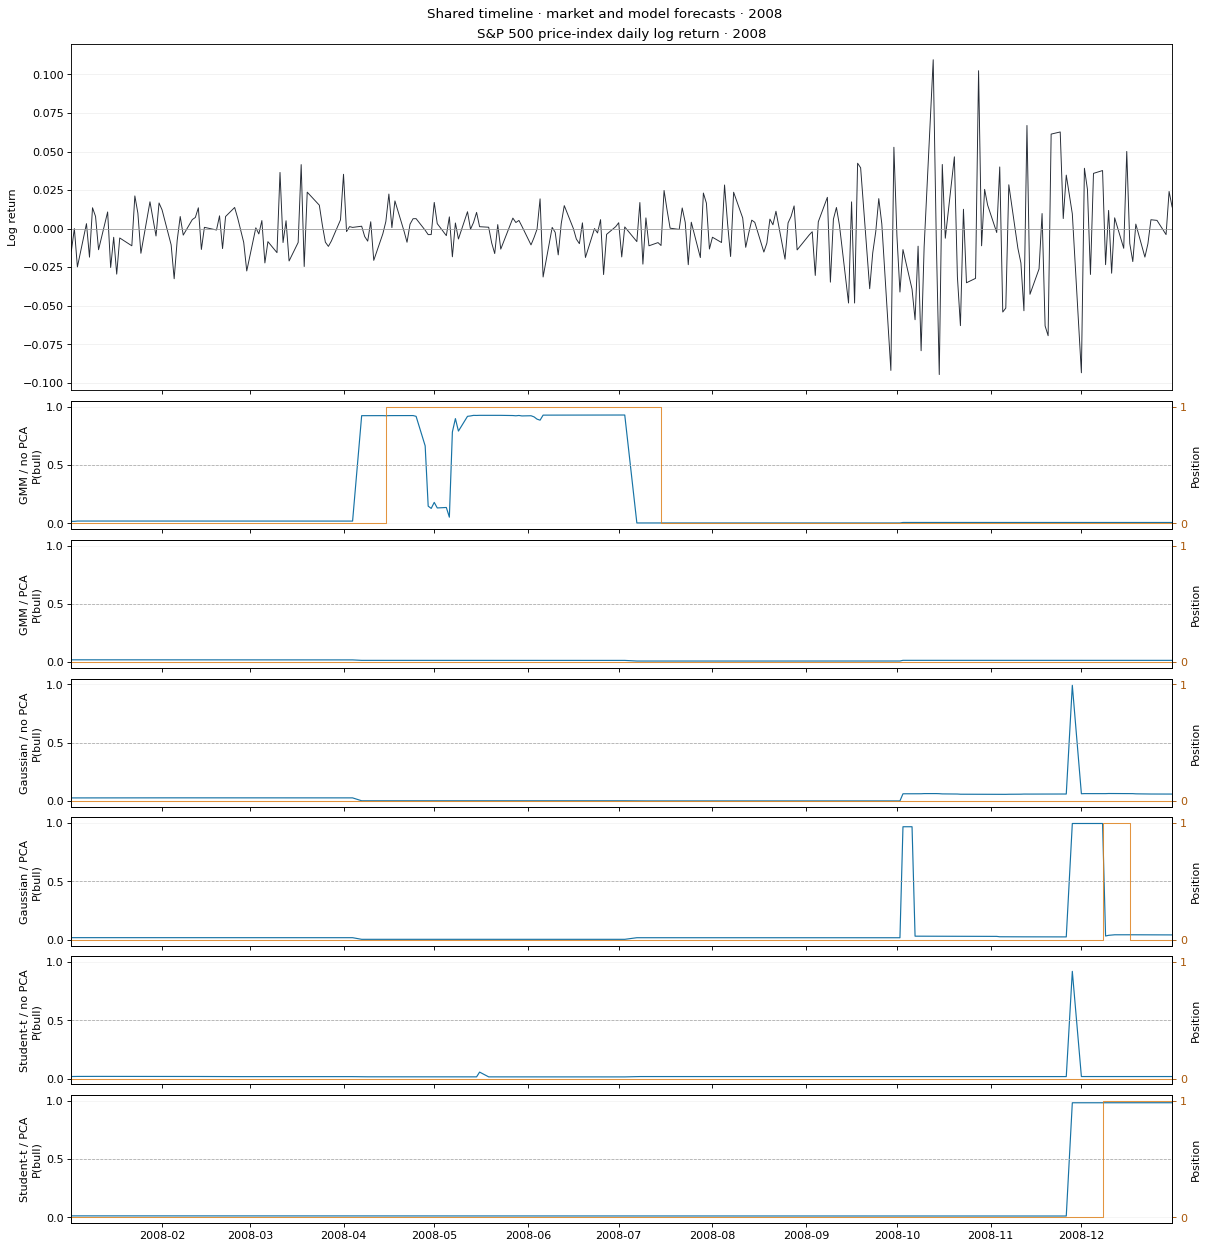

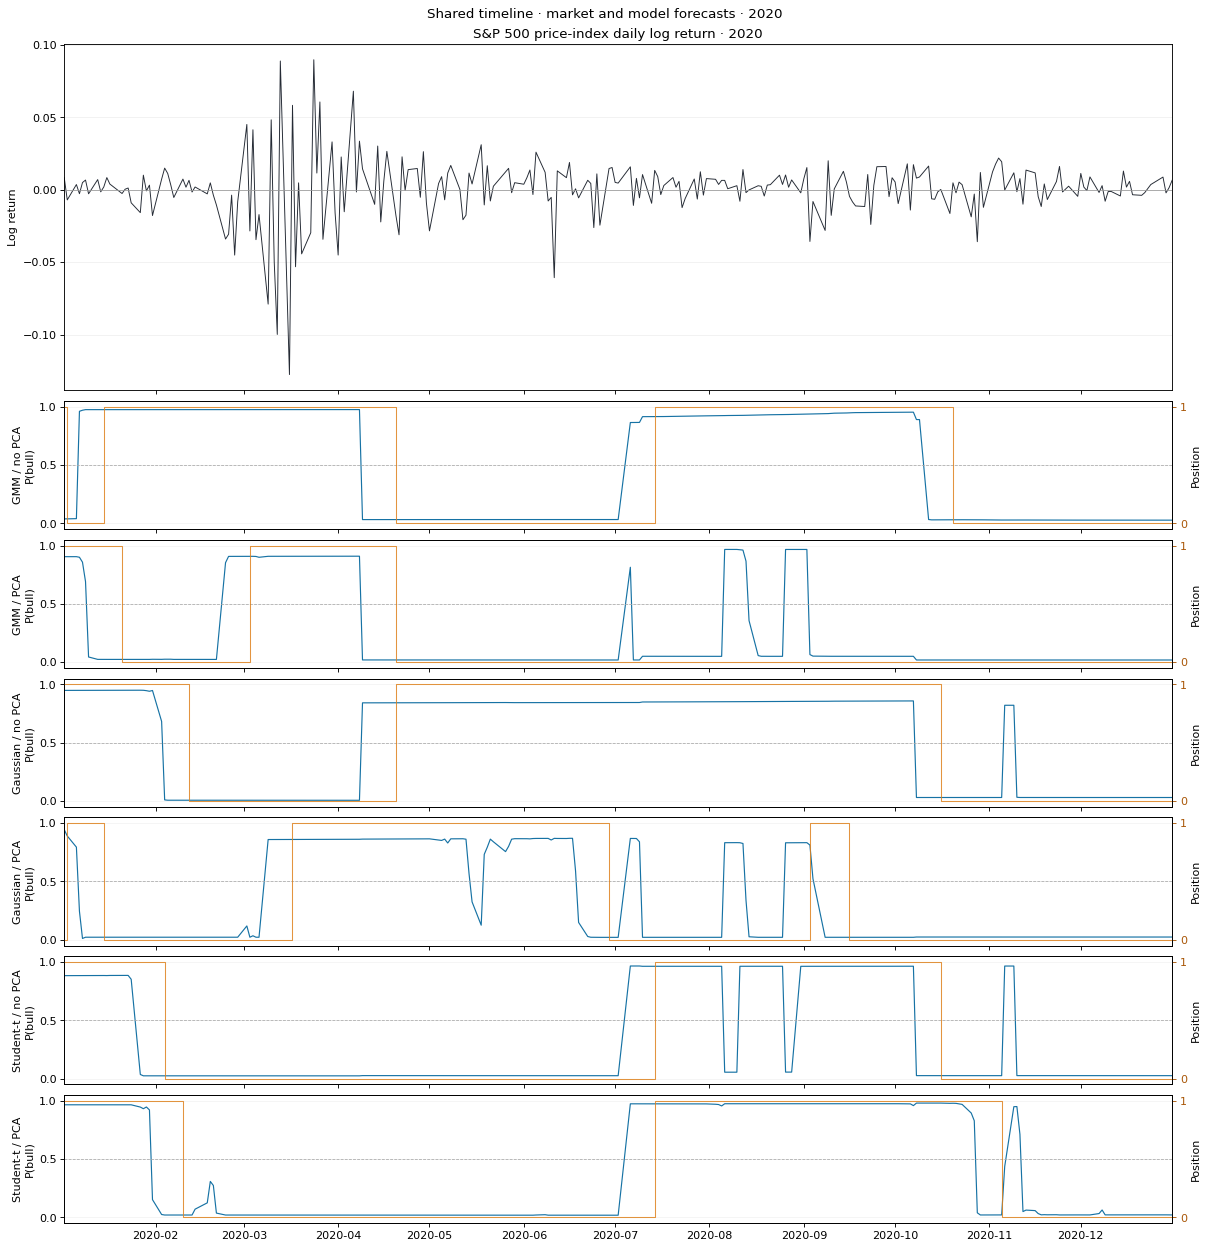

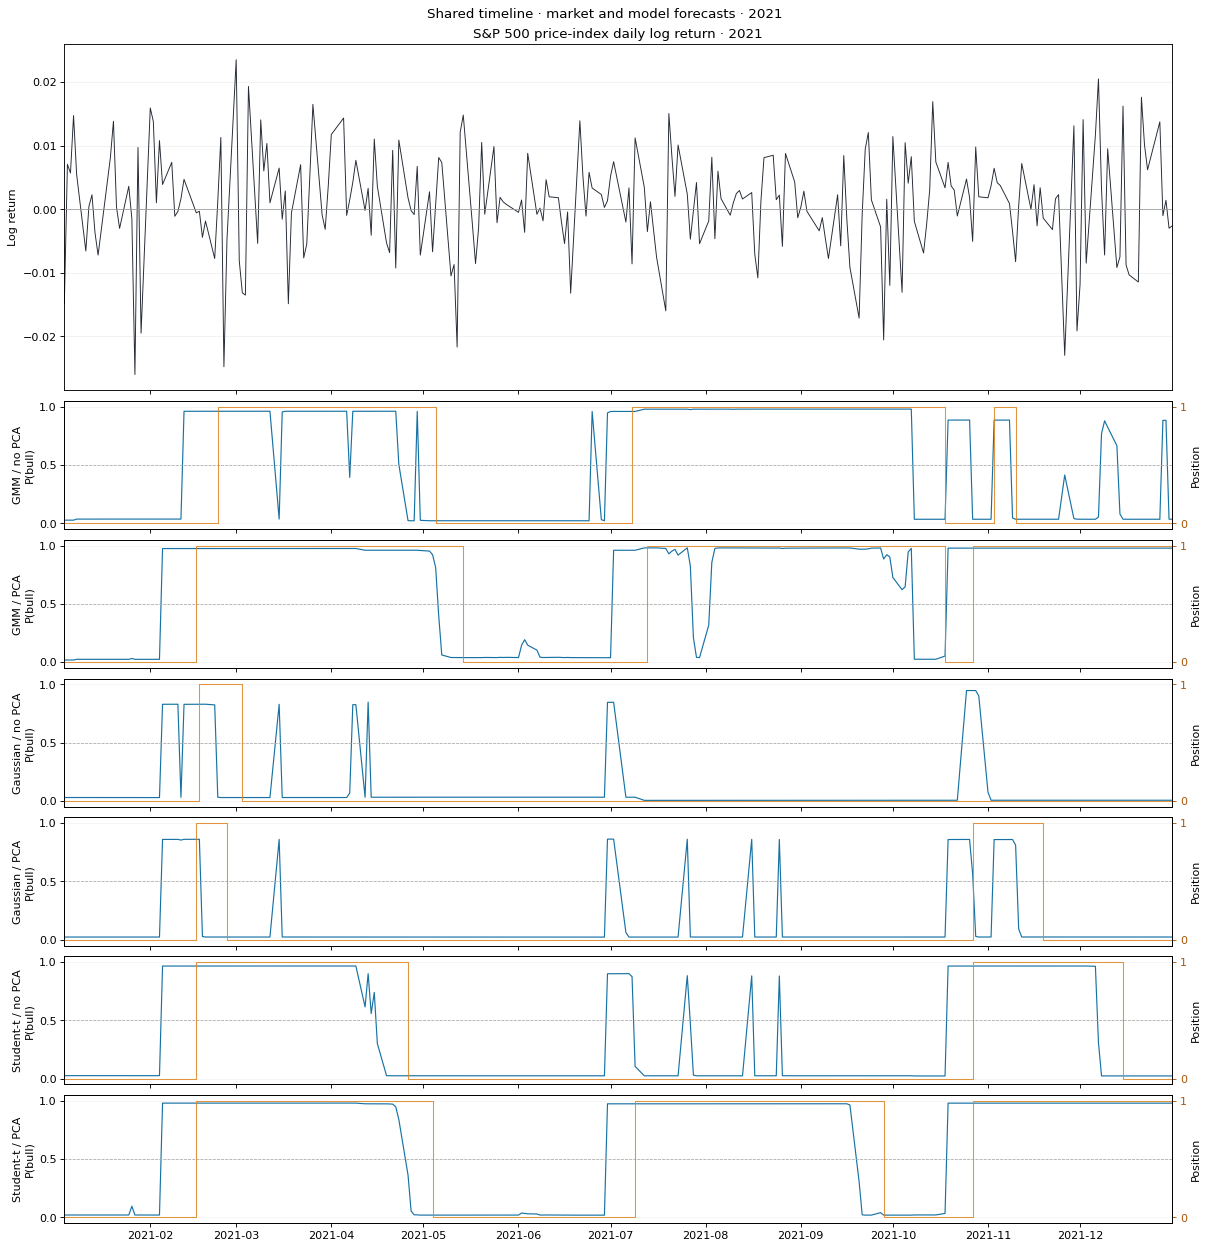

In [3]:
pnl, weights = evaluate_signals(fits, prices, median_window=12)

def run_lengths(values):
    values = np.asarray(values)
    boundaries = np.r_[0, np.flatnonzero(np.diff(values)) + 1, len(values)]
    return np.diff(boundaries)

rows = []
for (name, use_pca), group in fits.groupby(["model", "pca"]):
    key = f"{name} / {'PCA' if use_pca else 'no PCA'}"
    raw = group.sort_values("date")["bull_raw"].to_numpy()
    exposure = weights[key].to_numpy()
    raw_runs, exposure_runs = run_lengths(raw), run_lengths(exposure)
    rows.append({"model": key, "raw bull %": raw.mean() * 100,
                 "invested %": exposure.mean() * 100,
                 "raw switches/year": (len(raw_runs) - 1) * 252 / len(raw),
                 "position switches/year": (len(exposure_runs) - 1) * 252 / len(raw),
                 "median raw run": np.median(raw_runs),
                 "median position run": np.median(exposure_runs),
                 "mean position run": np.mean(exposure_runs)})
persistence = pd.DataFrame(rows).set_index("model")
display(persistence.round(2))
# Compute exposures on the complete series before selecting calendar years.
plot_years = (2008, 2020, 2021)
artifacts_dir = RESULT_DIR / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)
branches = list(fits.groupby(["model", "pca"], sort=True))


def plot_market(ax, returns, year):
    """Plot the price-index log return as a shared market reference."""
    ax.plot(returns.index, returns, color="#252b35", lw=0.85)
    ax.axhline(0, color="#999", lw=0.7)
    ax.set(title=f"S&P 500 price-index daily log return · {year}",
           ylabel="Log return")
    ax.grid(axis="y", alpha=0.18)


def plot_branch(ax, key, group):
    """Plot one branch's decision-date forecast and filtered position."""
    dates = group["date"]
    ax.plot(dates, group["bull_probability"], color="#1672a4", lw=1.05)
    ax.axhline(0.5, color="#aaa", ls="--", lw=0.7)
    ax.set(ylabel=f"{key}\nP(bull)", ylim=(-0.05, 1.05),
           yticks=[0, 0.5, 1])
    ax.grid(axis="y", alpha=0.13)
    position_ax = ax.twinx()
    position_ax.step(dates, weights[key].reindex(dates), where="post",
                     color="#de821e", lw=0.95, alpha=0.85)
    position_ax.set(ylim=(-0.05, 1.05), yticks=[0, 1], ylabel="Position")
    position_ax.tick_params(axis="y", colors="#a95708")


for year in plot_years:
    year_groups = [
        (name, use_pca, group.loc[group.date.dt.year.eq(year)])
        for (name, use_pca), group in branches
    ]
    if not any(not group.empty for _, _, group in year_groups):
        print(f"{year}: no saved decisions; skipped.")
        continue
    market_returns = np.log(prices).diff().loc[f"{year}-01-01":f"{year}-12-31"]
    fig, axes = plt.subplots(
        1 + len(year_groups), 1, figsize=(15, 15.5), sharex=True,
        gridspec_kw={"height_ratios": [2.7] + [1] * len(year_groups)},
        layout="constrained",
    )
    plot_market(axes[0], market_returns, year)
    for ax, (name, use_pca, group) in zip(axes[1:], year_groups):
        key = f"{name} / {'PCA' if use_pca else 'no PCA'}"
        if group.empty:
            ax.set_axis_off()
            continue
        plot_branch(ax, key, group)
        single, single_axes = plt.subplots(
            2, 1, figsize=(12, 6), sharex=True,
            gridspec_kw={"height_ratios": [2.7, 1]}, layout="constrained",
        )
        plot_market(single_axes[0], market_returns, year)
        plot_branch(single_axes[1], key, group)
        single_axes[-1].set_xlim(market_returns.index[0], market_returns.index[-1])
        filename = (f"persistence_{year}_{name.lower().replace('-', '_')}_"
                    f"{'pca' if use_pca else 'no_pca'}.png")
        single.savefig(artifacts_dir / filename, dpi=150)
        plt.close(single)
    axes[-1].set_xlim(market_returns.index[0], market_returns.index[-1])
    fig.suptitle(f"Shared timeline · market and model forecasts · {year}")
    fig.savefig(artifacts_dir / f"persistence_{year}_all_models.png", dpi=150)
    plt.show()
print(f"Saved model/year figures to {artifacts_dir}")


,total_return,sharpe,max_drawdown,exposure,turnover_per_year
Student-t / PCA,2.517,0.640,-0.214,0.456,5.009
Buy and hold,5.176,0.439,-0.568,1.000,0.000
GMM / no PCA,1.437,0.381,-0.339,0.430,3.871
GMM / PCA,1.386,0.356,-0.292,0.367,4.872
Student-t / no PCA,0.684,0.329,-0.160,0.288,3.552
Gaussian / no PCA,0.624,0.260,-0.226,0.204,2.049
Gaussian / PCA,0.606,0.243,-0.239,0.196,3.324


,cash on up days %,cash on down days %,"avoided losses, log pp","missed gains, log pp","net log advantage, pp"
model,,,,,
GMM / no PCA,56.58,57.54,1295.84,1388.81,-92.97
GMM / PCA,63.00,63.68,1331.93,1427.00,-95.08
Gaussian / no PCA,78.84,80.46,1607.20,1740.75,-133.55
Gaussian / PCA,80.19,80.74,1600.77,1735.46,-134.69
Student-t / no PCA,71.10,71.29,1573.07,1703.00,-129.93
Student-t / PCA,53.64,55.34,1343.60,1399.90,-56.29


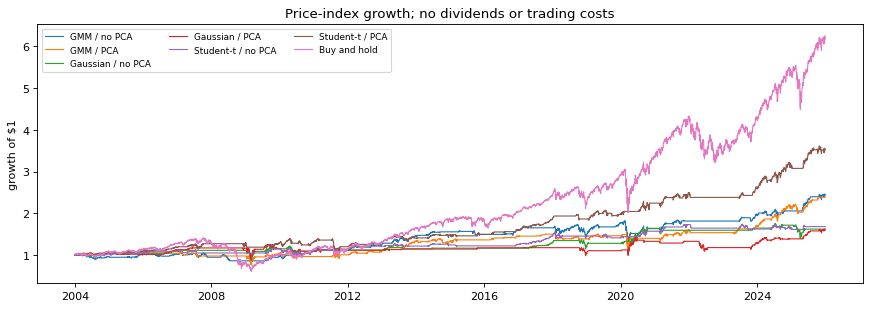

In [4]:
summary = compare_strategies(pnl, weights)
display(summary[["total_return", "sharpe", "max_drawdown", "exposure",
                 "turnover_per_year"]].round(3))

attribution = []
for key, exposure in weights.items():
    if key == "Buy and hold":
        continue
    r = next_return.reindex(exposure.index)
    cash = exposure.eq(0)
    cash_up = cash & r.gt(0)
    cash_down = cash & r.lt(0)
    advantage = pnl[key] - pnl["Buy and hold"]
    attribution.append({
        "model": key,
        "cash on up days %": 100 * cash_up.sum() / r.gt(0).sum(),
        "cash on down days %": 100 * cash_down.sum() / r.lt(0).sum(),
        "avoided losses, log pp": -100 * np.log1p(r[cash_down]).sum(),
        "missed gains, log pp": 100 * np.log1p(r[cash_up]).sum(),
        "net log advantage, pp": 100 * advantage.sum(),
    })
attribution = pd.DataFrame(attribution).set_index("model")
assert np.allclose(attribution["net log advantage, pp"],
                   attribution["avoided losses, log pp"]
                   - attribution["missed gains, log pp"])
display(attribution.round(2))
fig, ax = plt.subplots(figsize=(11, 4))
for key in pnl:
    ax.plot(pnl[key].index, np.exp(pnl[key].cumsum()), lw=1, label=key)
ax.set(title="Price-index growth; no dividends or trading costs", ylabel="growth of $1")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
plt.show()


In [5]:
forecast_rows = []
annual_rows = []
for (name, use_pca), group in fits.groupby(["model", "pca"]):
    key = f"{name} / {'PCA' if use_pca else 'no PCA'}"
    group = group.sort_values("date").set_index("date")
    r = next_return.reindex(group.index)
    exposure = weights[key].reindex(group.index)
    forecast_rows.append({"model": key, "bull forecast days": int(group.bull_raw.sum()),
                          "bear forecast days": int((1 - group.bull_raw).sum()),
                          "next-day return | bull %": 100 * r[group.bull_raw.eq(1)].mean(),
                          "next-day return | bear %": 100 * r[group.bull_raw.eq(0)].mean(),
                          "next-day return | invested %": 100 * r[exposure.eq(1)].mean(),
                          "next-day return | cash %": 100 * r[exposure.eq(0)].mean()})
    yearly = (pnl[key] - pnl["Buy and hold"]).groupby(group.index.year).agg(
        ["count", "sum"]
    )
    for year, values in yearly.iterrows():
        annual_rows.append({"year": year, "model": key, "days": int(values["count"]),
                            "log advantage, pp": 100 * values["sum"]})
display(pd.DataFrame(forecast_rows).set_index("model").round(4))
annual = pd.DataFrame(annual_rows)
display(annual.pivot(index=["year", "days"], columns="model",
                     values="log advantage, pp").round(2))


,bull forecast days,bear forecast days,next-day return | bull %,next-day return | bear %,next-day return | invested %,next-day return | cash %
model,,,,,,
GMM / no PCA,2460,3074,0.0488,0.0329,0.0427,0.0379
GMM / PCA,2044,3490,0.0343,0.0433,0.0495,0.0344
Gaussian / no PCA,1309,4225,0.0465,0.0379,0.0500,0.0374
Gaussian / PCA,1189,4345,0.0441,0.0388,0.0518,0.0371
Student-t / no PCA,1676,3858,0.0267,0.0458,0.0363,0.0415
Student-t / PCA,2521,3013,0.0550,0.0274,0.0533,0.0288


,model,GMM / PCA,GMM / no PCA,Gaussian / PCA,Gaussian / no PCA,Student-t / PCA,Student-t / no PCA
year,days,,,,,,
2004,252,-2.69,-11.80,-3.97,-2.15,0.04,-4.89
2005,252,-7.40,0.11,-7.78,-6.18,-3.99,-2.63
2006,251,-9.97,-10.44,-1.41,-6.20,-3.20,-8.17
2007,251,-8.55,-9.61,2.50,-1.14,4.80,-5.78
2008,253,44.02,34.64,43.44,44.02,46.42,44.02
2009,252,-13.12,-7.38,-20.48,-16.49,-20.06,-10.59
2010,252,-19.33,0.19,-16.97,-16.33,-9.86,-15.74
2011,252,3.77,2.11,1.78,1.78,-9.88,3.37
2012,250,-3.85,-0.95,-13.55,-13.55,-4.31,-7.94


## Next-day return separation by forecast and position

For each branch, compare mean **next-day S&P 500 price-index simple returns** on days forecast bull versus bear, and on days positioned invested versus cash. Each cell is the first conditional mean minus the second, displayed as a difference in %-valued daily returns (not a relative percentage improvement). The bull forecast uses $P(\text{bull}) \geq 0.5$; the invested/cash position uses the trailing 12-decision-day median, computed on the full sequence before any date selection. A decision made using prices through day $t$ is paired with the price return from $t$ to the next trading day. These are descriptive full-period associations, not a statistical significance test or a held-out model-selection claim.


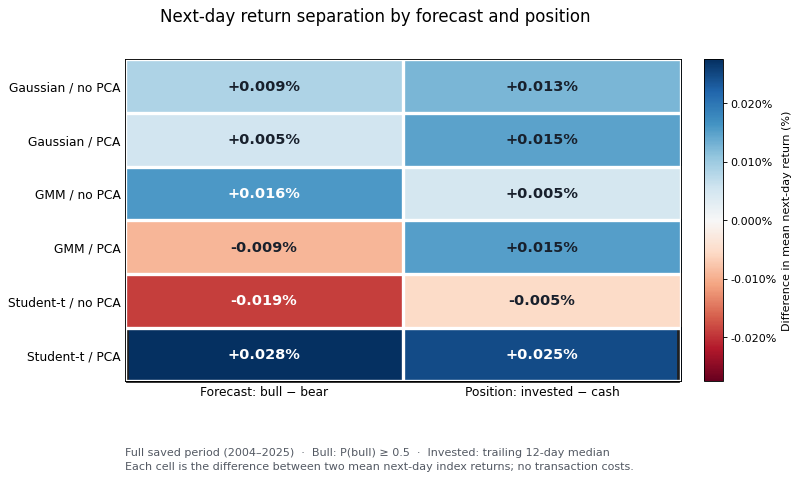

In [6]:
from matplotlib.colors import TwoSlopeNorm

comparison = pd.DataFrame(forecast_rows).set_index("model")
labels = [f"{name} / {'PCA' if use_pca else 'no PCA'}"
          for name in ("Gaussian", "GMM", "Student-t")
          for use_pca in (False, True)]
separation = pd.DataFrame({
    "Forecast: bull − bear": (comparison["next-day return | bull %"]
                              - comparison["next-day return | bear %"]),
    "Position: invested − cash": (comparison["next-day return | invested %"]
                                    - comparison["next-day return | cash %"]),
}).loc[labels]
values = separation.to_numpy()
limit = np.max(np.abs(values))
if not np.isfinite(limit) or limit <= 0:
    raise ValueError("Conditional-return differences must be finite and nonzero")

fig, ax = plt.subplots(figsize=(11.4, 6.15))
fig.subplots_adjust(left=.225, right=.835, top=.86, bottom=.205)
heat = ax.imshow(values, cmap="RdBu", aspect="auto",
                 norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit))
ax.set_xticks((0, 1), separation.columns, fontsize=11)
ax.set_yticks(range(len(labels)), labels, fontsize=11)
ax.tick_params(length=0)
ax.set_xticks(np.arange(-.5, 2, 1), minor=True)
ax.set_yticks(np.arange(-.5, len(labels), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=3)
ax.tick_params(which="minor", bottom=False, left=False)
for row in range(len(labels)):
    for col in range(2):
        ax.text(col, row, f"{values[row, col]:+.3f}%", ha="center", va="center",
                fontsize=13, fontweight="semibold",
                color="white" if abs(values[row, col]) > .55 * limit
                else "#18202c")
ax.add_patch(plt.Rectangle((-.49, 4.51), 1.98, .98, fill=False,
                           ec="#202020", lw=2.5, clip_on=False))
cax = fig.add_axes([.86, .205, .021, .655])
fig.colorbar(heat, cax=cax, format="%.3f%%",
             label="Difference in mean next-day return (%)")
fig.suptitle("Next-day return separation by forecast and position",
             fontsize=15, y=.965)
fig.text(.225, .055, "Full saved period (2004–2025)  ·  Bull: P(bull) ≥ 0.5  ·  Invested: trailing 12-day median",
         fontsize=10, color="#535963")
fig.text(.225, .025, "Each cell is the difference between two mean next-day index returns; no transaction costs.",
         fontsize=10, color="#535963")
artifacts_dir = RESULT_DIR / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(artifacts_dir / "conditional_next_day_return_heatmap.png", dpi=170)
plt.show()


## Year-by-year return separation

The full-period heatmap can conceal a result concentrated in a few years. Recalculate both differences **within each calendar year**, using the same saved next-day simple returns and full-history 12-day median positions as above. Values are differences between mean daily returns in `%` units, not annual strategy returns. A missing group is reported as `NaN`, not zero; group counts for the two Student-t branches accompany the differences. Yearly observations and overlapping regimes are not independent significance tests.


In [7]:
yearly_rows = []
for (name, use_pca), group in fits.groupby(["model", "pca"]):
    key = f"{name} / {'PCA' if use_pca else 'no PCA'}"
    group = group.sort_values("date").set_index("date")
    for year, portion in group.groupby(group.index.year):
        r = next_return.reindex(portion.index)
        bull = portion["bull_raw"].eq(1)
        invested = weights[key].reindex(portion.index).eq(1)

        def difference(mask):
            return 100 * (r[mask].mean() - r[~mask].mean()) if mask.any() and (~mask).any() else np.nan

        yearly_rows.append({
            "year": year, "model": key, "days": len(portion),
            "bull − bear %": difference(bull),
            "invested − cash %": difference(invested),
            "bull days": int(bull.sum()), "bear days": int((~bull).sum()),
            "invested days": int(invested.sum()), "cash days": int((~invested).sum()),
        })
yearly_separation = pd.DataFrame(yearly_rows).set_index(["year", "model"])
for measure in ("bull − bear %", "invested − cash %"):
    print(f"Yearly mean next-day return difference: {measure}")
    print(yearly_separation[measure].unstack("model")[labels].round(3).to_string())

print("Student-t: PCA minus no-PCA yearly separation (difference between two gaps, %)")
t_rows = yearly_separation.loc[(slice(None), ["Student-t / PCA", "Student-t / no PCA"]), :]
t_gap = pd.DataFrame({
    measure: (t_rows[measure].unstack("model")["Student-t / PCA"]
              - t_rows[measure].unstack("model")["Student-t / no PCA"])
    for measure in ("bull − bear %", "invested − cash %")
})
display(t_gap.round(3))
print("Student-t group sizes by year (check sparse or one-sided years)")
display(t_rows[["days", "bull days", "bear days", "invested days", "cash days"]])


Yearly mean next-day return difference: bull − bear %
model  Gaussian / no PCA  Gaussian / PCA  GMM / no PCA  GMM / PCA  Student-t / no PCA  Student-t / PCA
year                                                                                                  
2004               0.081           0.090        -0.005      0.136               0.116            0.079
2005              -0.059          -0.029         0.032     -0.077              -0.021           -0.094
2006               0.047           0.034        -0.094     -0.087              -0.006           -0.013
2007              -0.077          -0.081        -0.079     -0.144               0.052            0.085
2008              -8.824          -0.972        -0.022        NaN              -8.824            0.392
2009              -0.062          -0.084         0.148     -0.137               0.069           -0.030
2010              -0.158           0.152         0.117     -0.337              -0.293           -0.012
2011               

,bull − bear %,invested − cash %
year,,
2004,-0.037,0.006
2005,-0.073,-0.019
2006,-0.007,0.045
2007,0.033,0.169
2008,9.216,NaN
2009,-0.099,-0.259
2010,0.282,0.174
2011,0.383,-0.403
2012,0.024,0.002


,,days,bull days,bear days,invested days,cash days
year,model,,,,,
2004,Student-t / PCA,252,119,133,116,136
2005,Student-t / PCA,252,115,137,116,136
2006,Student-t / PCA,251,128,123,128,123
2007,Student-t / PCA,251,130,121,136,115
2008,Student-t / PCA,253,23,230,17,236
2009,Student-t / PCA,252,99,153,101,151
2010,Student-t / PCA,252,158,94,164,88
2011,Student-t / PCA,252,75,177,77,175
2012,Student-t / PCA,250,117,133,115,135


## Student-t forecasts and index level in 2008

Compare the **saved decision-date** Student-t $P(\text{bull})$ forecasts with and without PCA on a shared 2008 timeline. The bottom panel shows the S&P 500 **price-index level** (not SPY). The dashed line marks the $0.5$ bull threshold. Forecasts made on trading day $t$ predict the next trading day's return, so their date marks the decision, not the outcome. A near-zero forecast in most of 2008 means any bull-only return estimate can be highly sensitive to a handful of dates.


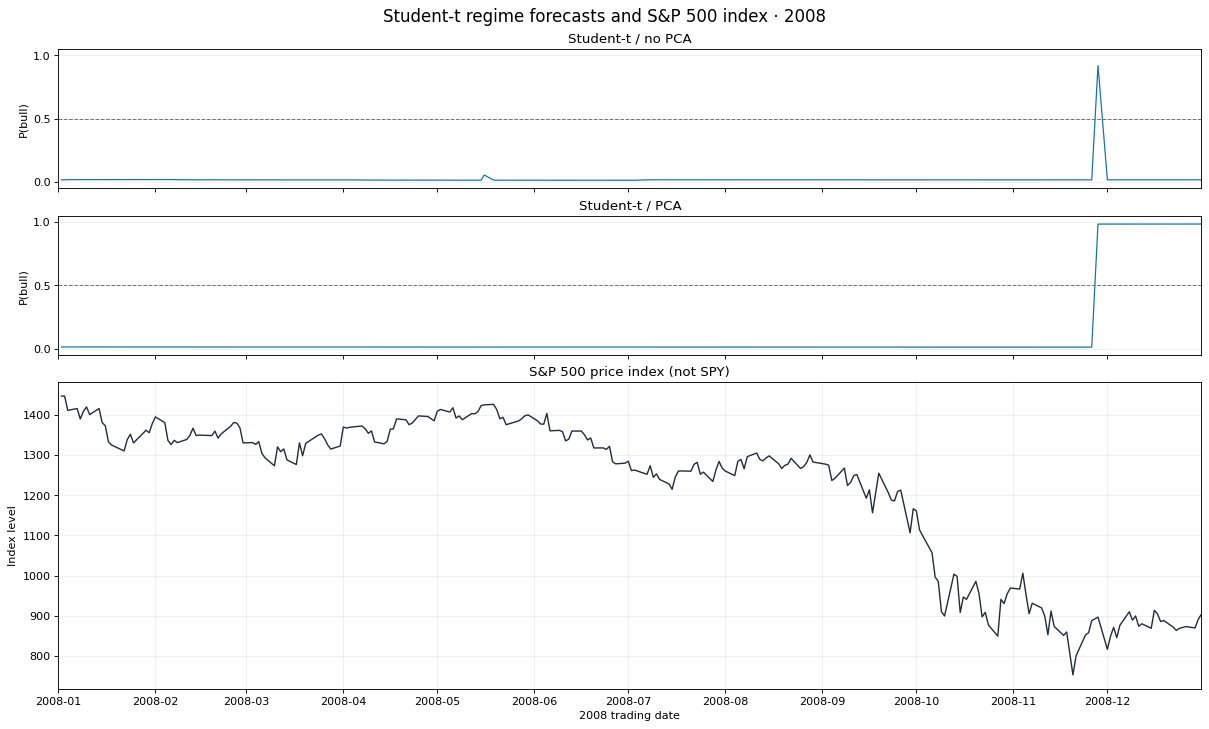

In [8]:
year_start = pd.Timestamp("2008-01-01")
year_end = pd.Timestamp("2008-12-31")
market_2008 = prices.loc[year_start:year_end]
if market_2008.empty:
    raise ValueError("The price series does not contain 2008")

fig, axes = plt.subplots(
    3, 1, figsize=(15, 9), sharex=True,
    gridspec_kw={"height_ratios": [1, 1, 2.2]}, layout="constrained",
)
for ax, use_pca, title in zip(
    axes[:2], (False, True), ("Student-t / no PCA", "Student-t / PCA")
):
    group = fits.loc[
        fits.model.eq("Student-t") & fits.pca.eq(use_pca)
        & fits.date.between(year_start, year_end)
    ].sort_values("date")
    if group.empty:
        raise ValueError(f"No saved 2008 forecasts for {title}")
    ax.plot(group.date, group.bull_probability, color="#1672a4", lw=1.1)
    ax.axhline(0.5, color="#777", linestyle="--", linewidth=0.9)
    ax.set(ylabel="P(bull)", ylim=(-0.05, 1.05), yticks=[0, 0.5, 1],
           title=title)
    ax.grid(axis="y", alpha=0.2)

axes[2].plot(market_2008.index, market_2008, color="#252b35", lw=1.25)
axes[2].set(title="S&P 500 price index (not SPY)", ylabel="Index level",
            xlabel="2008 trading date", xlim=(year_start, year_end))
axes[2].grid(alpha=0.2)
fig.suptitle("Student-t regime forecasts and S&P 500 index · 2008", fontsize=15)
artifacts_dir = RESULT_DIR / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(artifacts_dir / "student_t_pca_vs_no_pca_2008_index_bottom.png",
            dpi=160)
plt.show()


## Year-by-year strategy Sharpe variability

For each calendar year and branch, compute the annualized Sharpe of the **next-day, 0/1, 12-day median-smoothed strategy log PnL** used above: `sqrt(252) * daily_mean / daily_sample_std`, with zero risk-free rate, no dividends, financing or trading costs. Then report the unweighted mean and sample standard deviation of those **yearly Sharpe ratios** (not the standard deviation of daily returns or uncertainty of the mean). A year with no daily PnL variation has an undefined Sharpe and is excluded from the mean/SD; its count is shown. In particular, a cash-only year is *not* assigned a Sharpe of zero. The 2008 column and mean without 2008 help assess dependence on that year; these descriptive comparisons are not a significance test.


In [9]:
yearly_sharpe = {}
for name, log_pnl in pnl.items():
    yearly_sharpe[name] = {}
    for year, daily in log_pnl.groupby(log_pnl.index.year):
        daily = daily.dropna()
        volatility = daily.std(ddof=1)
        yearly_sharpe[name][year] = (
            np.sqrt(252) * daily.mean() / volatility
            if len(daily) >= 2 and np.isfinite(volatility) and volatility > 0
            else np.nan
        )
yearly_sharpe = pd.DataFrame(yearly_sharpe).sort_index()

sharpe_summary = pd.DataFrame({
    "avg yearly Sharpe": yearly_sharpe.mean(),
    "std yearly Sharpe": yearly_sharpe.std(ddof=1),
    "valid years": yearly_sharpe.count(),
    "undefined years": yearly_sharpe.isna().sum(),
    "2008 Sharpe": yearly_sharpe.loc[2008],
    "avg excluding 2008": yearly_sharpe.drop(index=2008).mean(),
}).loc[labels + ["Buy and hold"]]
print("Annualized Sharpe in each calendar year (NaN = zero daily variation):")
print(yearly_sharpe[labels + ["Buy and hold"]].round(3).to_string())
print("\nYearly Sharpe summary (equal weighting across defined years):")
print(sharpe_summary.round(3).to_string())
print("\nStudent-t PCA − no-PCA Sharpe, on paired years with both defined:")
paired_difference = (
    yearly_sharpe["Student-t / PCA"] - yearly_sharpe["Student-t / no PCA"]
).dropna()
print(f"{len(paired_difference)} paired years; mean difference "
      f"{paired_difference.mean():+.3f}; std difference "
      f"{paired_difference.std(ddof=1):.3f}")
print("2008 Student-t invested-day fractions: "
      + ", ".join(
          f"{name}: {weights[name].loc['2008'].mean():.1%}"
          for name in ("Student-t / no PCA", "Student-t / PCA")
      ))


Annualized Sharpe in each calendar year (NaN = zero daily variation):
      Gaussian / no PCA  Gaussian / PCA  GMM / no PCA  GMM / PCA  Student-t / no PCA  Student-t / PCA  Buy and hold
2004              0.828           0.627        -0.459      0.973               0.910            1.197         0.729
2005             -0.153          -0.449         0.860     -0.478               0.391            0.210         0.521
2006              1.388           2.146         0.070      0.571               0.571            1.336         1.117
2007              0.943           1.210        -0.554     -0.777              -0.430            0.622         0.133
2008                NaN          -0.088        -1.062        NaN                 NaN            0.284        -1.066
2009              0.135          -0.041         1.572      0.277               1.219           -0.045         0.720
2010             -0.363          -0.855         1.056     -0.534              -0.243            0.128         0.641
20

## Historical Student-t emission parameters: 2008

The checkpoint saves only the latest fitted models, so the **2008 parameters below are reconstructed by replaying** the previous October 2007 refit, each 2008 scheduled full refit, and daily continuation updates. The replay compares each bull forecast against its saved decision row. Vertical markers show full refits (January 4, April 7, July 7, and October 3); emission parameters can also change on other days. This in-memory replay may take several minutes. The two charts are generated by the following notebook cell; no separate image or CSV file is needed.

The first chart displays Student-t bull/bear degrees of freedom (df) and S&P 500 daily log returns. The second displays the **mean-vector norm** and **median marginal standard deviation** for the two states and PCA branches above the same index returns. Lower df means heavier tails, **not** a more persistent Markov state. The PCA bull df of 2.1 is at the fitting lower bound.

For a Student-t coordinate with df $\nu>2$ and scale-matrix diagonal $S_{ii}$, its marginal std is $\sqrt{S_{ii}\nu/(\nu-2)}$; the full model also has off-diagonal scale entries. PCA locations/stds are in principal-component coordinates; no-PCA values are in standardized-feature coordinates. Their magnitudes are **not directly comparable** across branches. The selected-date table following the plots gives the fitted df and summary statistics, not a scalar return mean or a historical time-series std. The per-coordinate table can be explored directly in the notebook via `coordinate_parameters` without exporting a CSV.


Validated 253 2008 trading dates; maximum forecast difference: 2.44e-14


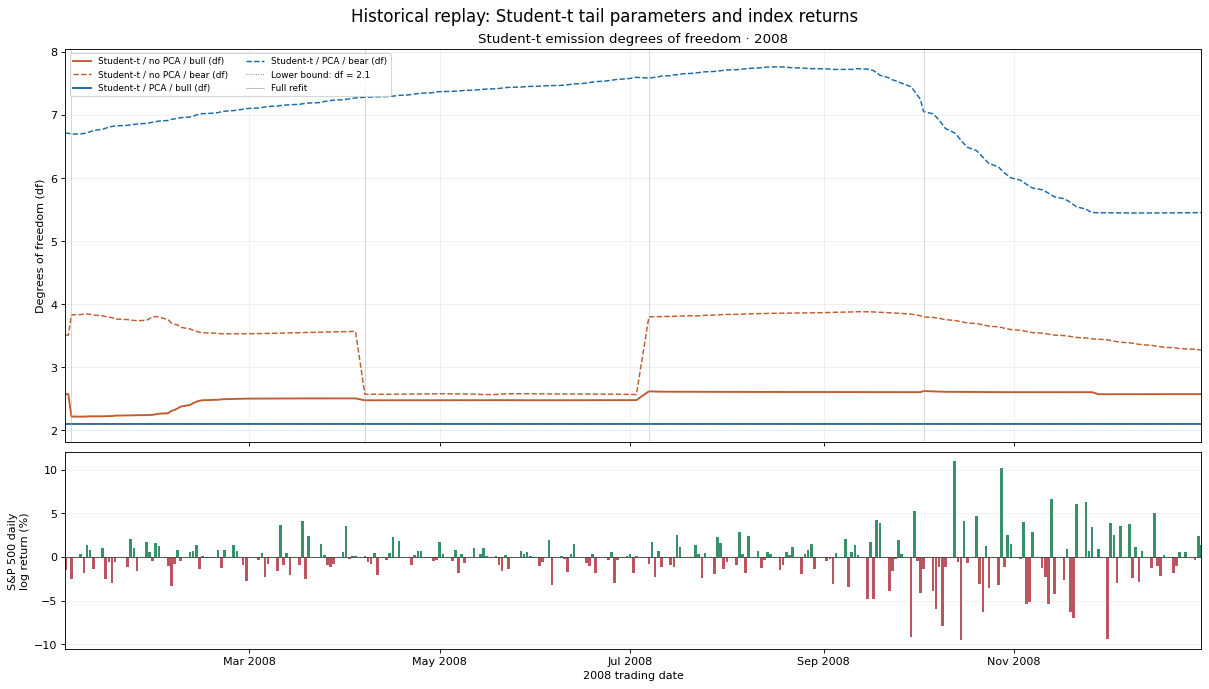

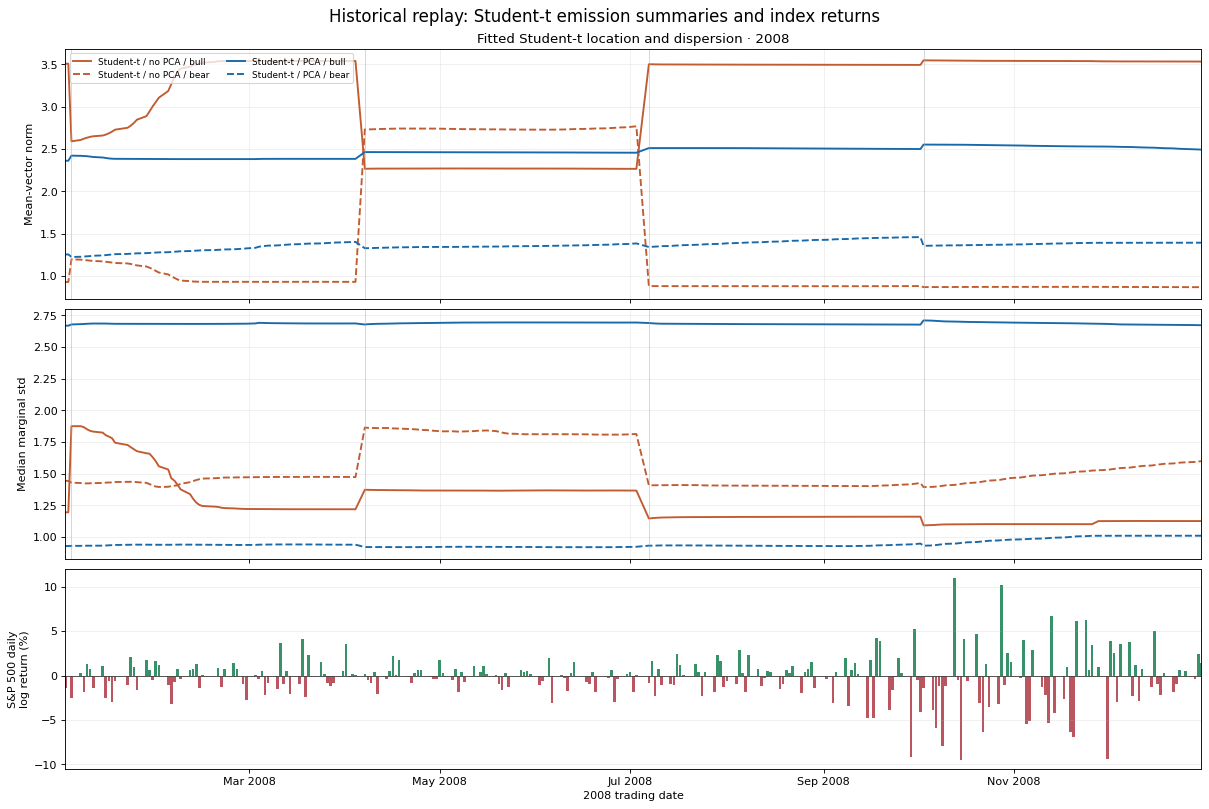

In [10]:
from plot_2008_student_t_emissions import draw_figures, replay_emissions

emission_daily, coordinate_parameters, return_marginals = replay_emissions(
    fits, prices
)
print(f"Validated {emission_daily.date.nunique()} 2008 trading dates; "
      f"maximum forecast difference: "
      f"{emission_daily.max_forecast_error.max():.3g}")
draw_figures(emission_daily, prices)


### Return-feature marginals: September 2 and December 31, 2008

September 1 was a market holiday, so September 2 is the first September trading decision. Each panel overlays the bull and bear Student-t **one-dimensional marginal** of the standardized return feature; the dates are decision-date fits using information available through that date. For PCA, this is the marginal obtained by projecting the retained-PC Student-t fit back onto the standardized return feature (discarded components are not restored). A marginal is not the full multivariate emission or the distribution of raw S&P 500 returns. Panels share axis scales for comparison.


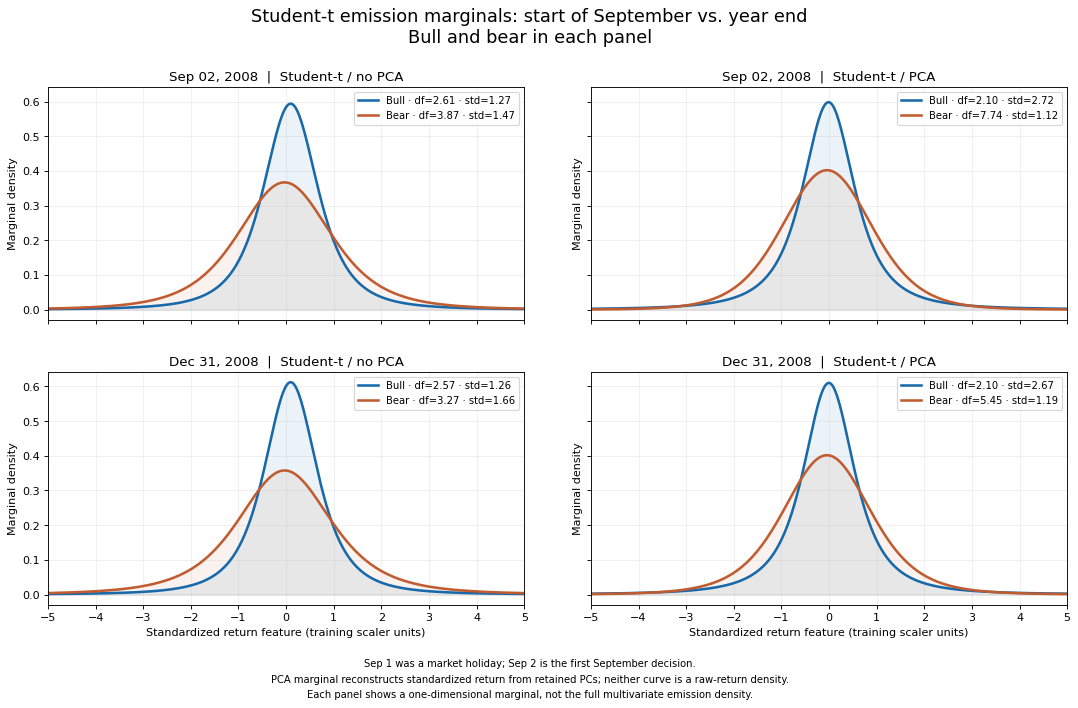

In [11]:
from plot_2008_student_t_emissions import draw_return_marginals

draw_return_marginals(return_marginals)


### Gaussian and GMM return-feature marginals: September 2 and December 31, 2008

The two four-panel figures match the Student-t comparison above: rows are decision-date fits from September 2 and December 31; columns show no PCA and PCA; bull and bear curves share each panel. September 1 was a market holiday. Every panel shows the **marginal density of the standardized return feature** on the same $[-5,5]$ x-axis, not a raw index-return density. The PCA curve is the marginal projected back from retained principal components; omitted components are not reconstructed.

The Gaussian state curve is a single projected normal density. Each GMM **state** curve is the weighted sum of its two projected Gaussian components, using that state's fitted mixture weights (not the HMM state probability). Historical parameters are reconstructed from scheduled refits and daily continuation updates, with bull forecasts checked against the checkpoint; the checkpoint itself remains unchanged.


Gaussian/GMM replay maximum forecast difference: 3.2e-14


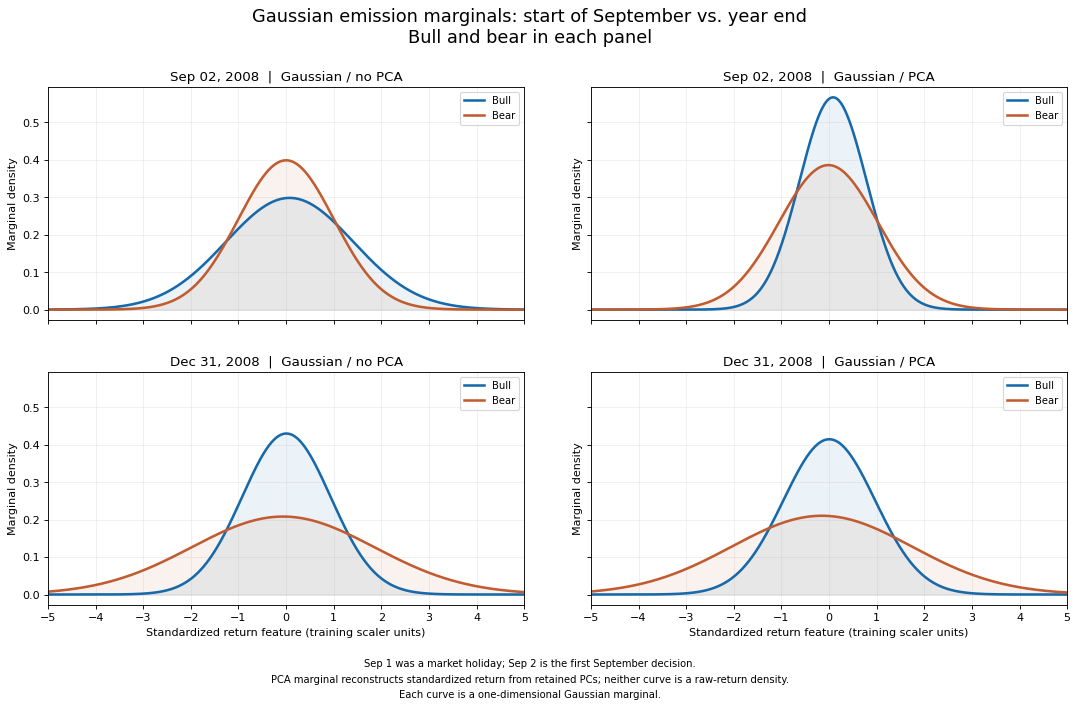

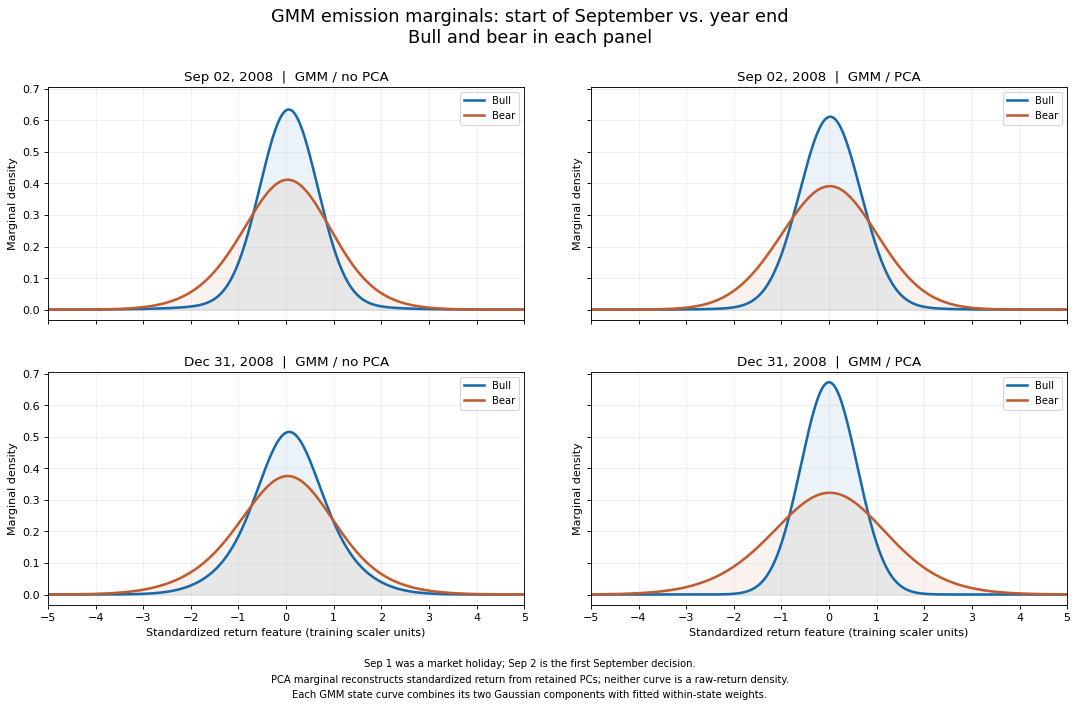

In [12]:
from plot_2008_gaussian_gmm_marginals import draw_marginals, replay_marginals

normal_marginals = replay_marginals(fits, prices)
print("Gaussian/GMM replay maximum forecast difference: "
      f"{normal_marginals.forecast_error.max():.3g}")
draw_marginals(normal_marginals, "Gaussian")
draw_marginals(normal_marginals, "GMM")


In [13]:
selected_dates = [
    "2008-10-03", "2008-11-26", "2008-11-28", "2008-12-01", "2008-12-31"
]
parameter_summary = emission_daily.loc[
    emission_daily.date.isin(pd.to_datetime(selected_dates))
]
assert len(parameter_summary) == 2 * len(selected_dates)
parameter_summary = pd.concat([
    parameter_summary[["date", "branch", "components", f"{state}_df",
                       f"{state}_mean_norm", f"{state}_median_std"]]
    .rename(columns={f"{state}_df": "Degrees of freedom",
                     f"{state}_mean_norm": "Mean-vector norm",
                     f"{state}_median_std": "Median marginal std"})
    .assign(State=state)
    for state in ("bull", "bear")
]).sort_values(["date", "branch", "State"])
display(parameter_summary.rename(columns={
    "date": "Decision date", "branch": "Student-t branch",
    "components": "Coordinates",
}).reset_index(drop=True).round(3))


,Decision date,Student-t branch,Coordinates,Degrees of freedom,Mean-vector norm,Median marginal std,State
0,2008-10-03,Student-t / PCA,11,7.056,1.355,0.932,bear
1,2008-10-03,Student-t / PCA,11,2.100,2.551,2.710,bull
2,2008-10-03,Student-t / no PCA,28,3.796,0.868,1.395,bear
3,2008-10-03,Student-t / no PCA,28,2.621,3.546,1.093,bull
4,2008-11-26,Student-t / PCA,11,5.455,1.391,1.010,bear
5,2008-11-26,Student-t / PCA,11,2.100,2.528,2.686,bull
6,2008-11-26,Student-t / no PCA,28,3.449,0.870,1.525,bear
7,2008-11-26,Student-t / no PCA,28,2.603,3.537,1.102,bull
8,2008-11-28,Student-t / PCA,11,5.451,1.391,1.011,bear
9,2008-11-28,Student-t / PCA,11,2.100,2.528,2.684,bull
